# 03 · Definitions and features

**Question this notebook answers:** turn the cleaned shots into the frozen analysis table: shot pairs,
streak states, the calibration/analysis split, shot difficulty (xFG), each player's own baseline,
playstyle clusters and segment labels.

Every definition is Massimo's and is logged in `docs/decisions.md` (D-006 to D-035). Nothing here
compares shots after makes with shots after misses: that starts in Stage 5.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from hothand import clusters, features, xfg
from hothand.config import FIGURES, load_config
from hothand.pairs import ZONE_NAMES, flag_shots, load_cleaned, load_game_split

pd.set_option("display.max_columns", 40, "display.width", 200)
cfg = load_config()
print("Python:", sys.executable)
print("pandas:", pd.__version__)

Python: /Users/massimovitale/Desktop/nba-shot-selection-hot-hand/.venv/bin/python
pandas: 3.0.6


## 1. Build the feature table

In [2]:
f = features.build()
print(f"{len(f):,} pairs, {f.shape[1]} columns")
f.groupby(["half", "season_type"]).size().unstack()

1,071,022 pairs, 75 columns


season_type,Playoffs,Regular Season
half,,
analysis,34353,501306
calibration,34695,500668


## 2. Shot difficulty (xFG): model comparison on held-out calibration games

20% of calibration-half games are held out; both candidate models are fitted on the rest. The
analysis half is never used. Massimo chose the logistic regression (D-032).

In [3]:
shots = flag_shots(load_cleaned(cfg), cfg).merge(load_game_split(), on="game_id")
cal = shots[(shots.half == "calibration") & shots.in_analysis_population]
games = np.sort(cal.game_id.unique())
rng = np.random.default_rng(cfg["random_seed"])
hold = set(rng.choice(games, int(0.2 * len(games)), replace=False))
tr, te = cal[~cal.game_id.isin(hold)], cal[cal.game_id.isin(hold)]
keep = set(tr.action_type.value_counts()[lambda v: v >= cfg["xfg"]["min_action_count"]].index)
dist = cfg["features"]["distance_column"]
Xtr = xfg.pool_rare_actions(xfg.design(tr, dist), keep)
Xte = xfg.pool_rare_actions(xfg.design(te, dist), keep)
preds, rows = {}, []
for name, make in [("logistic", xfg.logistic_model), ("boosted", xfg.boosted_model)]:
    preds[name] = make(cfg["random_seed"]).fit(Xtr, tr.shot_made).predict_proba(Xte)[:, 1]
    rows.append({"model": name, **xfg.evaluate(te.shot_made.to_numpy(), preds[name])})
pd.DataFrame(rows).round(4)

,model,log_loss,brier,auc,mean_pred,mean_obs
0,logistic,0.6378,0.2244,0.6542,0.4610,0.4617
1,boosted,0.6360,0.2236,0.6574,0.4611,0.4617


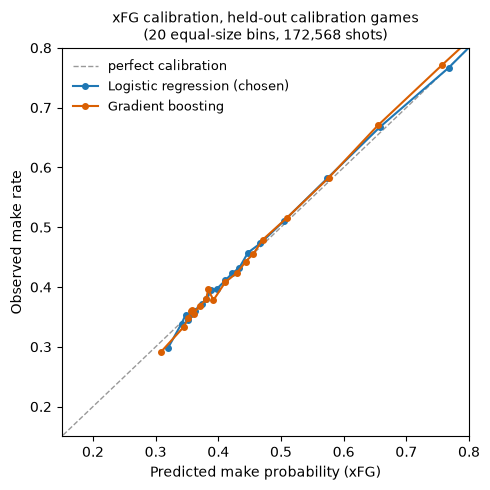

In [4]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], color="#999", lw=1, ls="--", label="perfect calibration")
for name, label, color in [("logistic", "Logistic regression (chosen)", "#1f77b4"),
                           ("boosted", "Gradient boosting", "#d95f02")]:
    t = xfg.calibration_table(te.shot_made.to_numpy(), preds[name])
    ax.plot(t.pred, t.obs, "o-", ms=4, color=color, label=label)
ax.set_xlabel("Predicted make probability (xFG)")
ax.set_ylabel("Observed make rate")
ax.set_title(f"xFG calibration, held-out calibration games\n(20 equal-size bins, {len(te):,} shots)",
             fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax.set_xlim(0.15, 0.8); ax.set_ylim(0.15, 0.8)
fig.tight_layout()
fig.savefig(FIGURES / "stage4_xfg_calibration.png", dpi=150)

## 3. Playstyle clusters: choice of k and stability

Fitted on calibration-half regular-season shots of player-seasons with at least 200 such shots
(D-034). Stability compares each fit with the reference fit by the adjusted Rand index (1 = same
grouping) across seeds and bootstrap resamples. Massimo chose k = 4 (D-033).

In [5]:
seg = cfg["segments"]
cal_rs = shots[(shots.half == "calibration") & shots.in_analysis_population
               & (shots.season_type == "Regular Season")]
shares = clusters.zone_shares(cal_rs, seg["cluster_min_fga_season"])
X = shares[ZONE_NAMES].to_numpy()
stability = clusters.compare_k(X, seg["cluster_k_candidates"], cfg["random_seed"],
                               seg["cluster_stability_seeds"], seg["cluster_bootstrap_resamples"])
stability.to_csv("../reports/stage4_cluster_stability.csv", index=False)
stability.round(3)

,k,silhouette,seed_ari_min,boot_ari_median,boot_ari_p10,smallest_cluster,largest_cluster
0,3,0.263,0.968,0.933,0.844,261,812
1,4,0.254,0.968,0.880,0.787,204,565
2,5,0.222,0.407,0.527,0.357,157,455
3,6,0.216,0.636,0.554,0.410,109,410
4,7,0.225,0.812,0.703,0.500,98,402


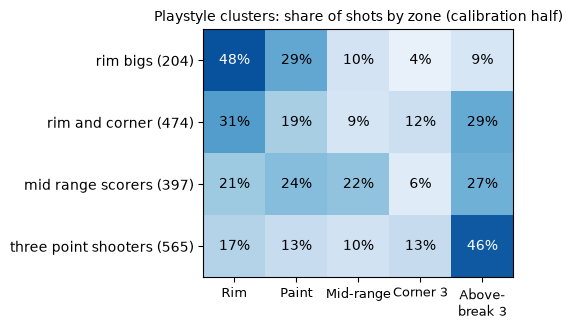

In [6]:
cl = pd.read_csv(features.CLUSTERS)
prof = cl.groupby("cluster")[ZONE_NAMES].mean().mul(100)
prof = prof.loc[["rim_bigs", "rim_and_corner", "mid_range_scorers", "three_point_shooters"]]
fig, ax = plt.subplots(figsize=(8, 3.4))
im = ax.imshow(prof.to_numpy(), cmap="Blues", vmin=0, vmax=55)
ax.set_xticks(range(5), ["Rim", "Paint", "Mid-range", "Corner 3", "Above-\nbreak 3"], fontsize=9)
ax.set_yticks(range(4), [f"{c.replace('_', ' ')} ({(cl.cluster == c).sum()})" for c in prof.index])
for i in range(4):
    for j in range(5):
        v = prof.iloc[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 35 else "black")
ax.set_title("Playstyle clusters: share of shots by zone (calibration half)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES / "stage4_cluster_profiles.png", dpi=150)

## 4. Cell sizes for the segment comparisons (analysis half)

Minimum per cell: 30 players and 2,000 pairs (D-011). Cells below it are reported as "too few shots to
estimate". This counts pairs only; it does not look at any outcome.

In [7]:
a = f[f.half == "analysis"]
cells = []
for col in ["experience_group", "usage_tier", "cluster"]:
    for (st, g), x in a.groupby(["season_type", col]):
        cells.append({"segment": col, "season_type": st, "group": g, "pairs": len(x),
                      "players": x.player_id.nunique()})
cells = pd.DataFrame(cells)
inf = cfg["inference"]
cells["meets_minimum"] = (cells.pairs >= inf["min_pairs_per_cell"]) & (cells.players >= inf["min_players_per_cell"])
cells.to_csv("../reports/stage4_cell_sizes.csv", index=False)
cells

,segment,season_type,group,pairs,players,meets_minimum
0,experience_group,Playoffs,rookie,865,106,False
1,experience_group,Playoffs,veteran,9336,149,True
2,experience_group,Regular Season,rookie,40409,728,True
3,experience_group,Regular Season,veteran,106185,229,True
4,usage_tier,Playoffs,high,25136,203,True
5,usage_tier,Playoffs,low,2116,263,True
6,usage_tier,Playoffs,mid,6823,247,True
7,usage_tier,Regular Season,high,314859,303,True
8,usage_tier,Regular Season,low,51038,570,True
9,usage_tier,Regular Season,mid,125945,513,True
